# NumPy MLP From Scratch: Fashion-MNIST

## Milestone 1: Prepare the data

This notebook will use NumPy for all neural-network math. In this milestone, we only load, inspect, split, flatten, and normalize the data. We will not build or train a model yet.

## Data contract

- Training: 55,000 images used to learn weights and biases later.
- Validation: 5,000 images used later to choose settings fairly.
- Test: 10,000 official test images, untouched until the final evaluation.

Fashion-MNIST has 10 clothing classes. Each grayscale image is 28 by 28 pixels.

In [13]:
from pathlib import Path

import matplotlib.pyplot as plt

import numpy as np

# torchvision to download and read Fashion-MNST.
from torchvision import datasets

PROJECT_ROOT = Path.cwd()

DATA_DIR = PROJECT_ROOT / "data"

SPLIT_DIR = PROJECT_ROOT / "splits"

# A seed makes random choices repeatable every time we run the notebook.
SEED = 42

NUM_TRAIN = 55_000

NUM_VALIDATION = 5_000

CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
]

rng = np.random.default_rng(SEED) # Create a random number generator with a fixed seed for reproducibility.

print(f"Project root: {PROJECT_ROOT}")

Project root: /home/qtg6528/AI/scratch_projects/numpy_mlp_fashion_mnist


In [14]:
official_train_dataset = datasets.FashionMNIST(
    root=DATA_DIR,
    # train=True chooses the official 60,000-image training portion.
    train=True,
    # download=True downloads files only if they are not already present.
    download=True,
)

# Download and load the separate 10,000-image official test set.
official_test_dataset = datasets.FashionMNIST(
    # Use the same data folder.
    root=DATA_DIR,
    # train=False chooses the official test portion.
    train=False,
    # Download files if needed.
    download=True,
)

# Check that Fashion-MNIST gave us the expected two dataset sizes.
print(f"Official training images: {len(official_train_dataset):,}")
print(f"Official test images: {len(official_test_dataset):,}")

Official training images: 60,000
Official test images: 10,000


Raw image shape: (60000, 28, 28)
Raw image dtype: uint8
Raw label shape: (60000,)
Examples per class: [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


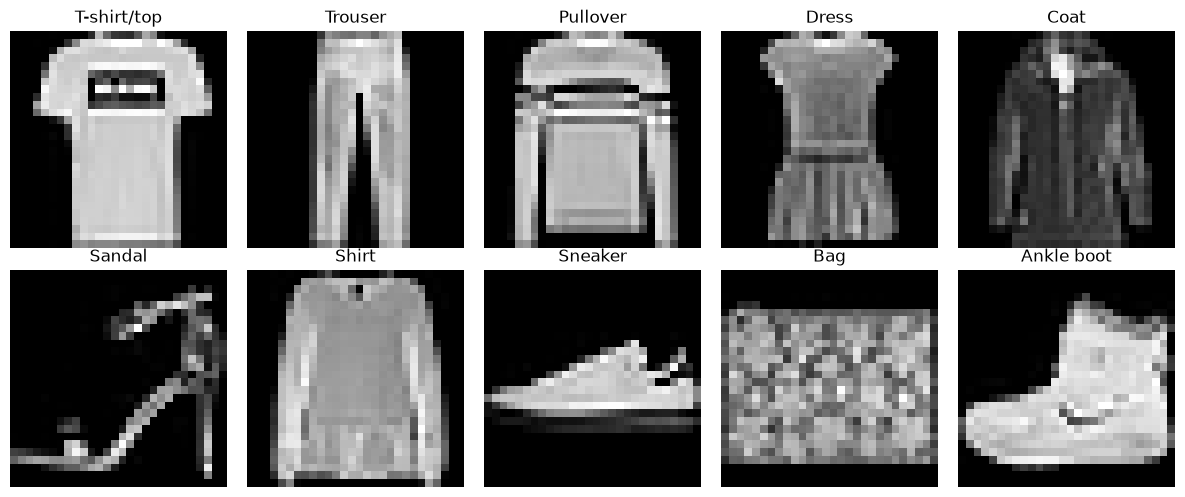

In [15]:
# Convert the image tensor into a NumPy array so we can use NumPy everywhere else.
raw_images = official_train_dataset.data.numpy()

# Convert the matching clothing-label tensor into a NumPy array too.
raw_labels = official_train_dataset.targets.numpy()

# Show the dataset structure before changing anything.
print(f"Raw image shape: {raw_images.shape}")
print(f"Raw image dtype: {raw_images.dtype}")
print(f"Raw label shape: {raw_labels.shape}")

# np.bincount counts how many examples have label 0, label 1, and so on.
print("Examples per class:", np.bincount(raw_labels))

# Make a small grid with 2 rows and 5 columns for the 10 classes.
figure, axes = plt.subplots(2, 5, figsize=(12, 5))

# axes.flat lets us visit every small plot one at a time.
for class_id, axis in enumerate(axes.flat):
    # Find the row number of the first image that has this class label.
    image_numbers_for_this_class = np.flatnonzero(raw_labels == class_id)
    first_image_number = image_numbers_for_this_class[0]

    # Draw that one grayscale clothing image.
    axis.imshow(raw_images[first_image_number], cmap="gray")

    # Put the human-readable clothing name above the image.
    axis.set_title(CLASS_NAMES[class_id])

    # Hide x and y tick marks because they do not help us inspect the image.
    axis.axis("off")

# Prevent plot titles and images from overlapping.
plt.tight_layout()
plt.show()

In [16]:
# Make two empty lists. We will fill them with row numbers from the original data.
validation_indices_by_class = []
training_indices_by_class = []

# Repeat the same process for each label number: 0, 1, ..., 9.
# len(CLASS_NAMES) is already available here, before the model is created.
for class_id in range(len(CLASS_NAMES)):
    # Find every original row number that belongs to this clothing class.
    row_numbers_for_this_class = np.flatnonzero(raw_labels == class_id)

    # Shuffle those row numbers using our seeded random generator.
    # The seed means this shuffle will be identical whenever we run from the top.
    shuffled_row_numbers = rng.permutation(row_numbers_for_this_class)

    # Put the first 500 shuffled images of this class into validation.
    validation_indices_by_class.append(shuffled_row_numbers[:500])

    # Put the remaining 5,500 images of this class into training.
    training_indices_by_class.append(shuffled_row_numbers[500:])

# Join the 10 class-specific pieces into one validation-index array.
validation_indices = np.concatenate(validation_indices_by_class)

# Join the 10 class-specific pieces into one training-index array.
training_indices = np.concatenate(training_indices_by_class)

# Check the two groups have the sizes promised in the project plan.
assert len(training_indices) == NUM_TRAIN
assert len(validation_indices) == NUM_VALIDATION

# Check that an image cannot appear in both groups.
assert len(np.intersect1d(training_indices, validation_indices)) == 0

# Create the splits folder if it does not already exist.
SPLIT_DIR.mkdir(exist_ok=True)

# Choose a clear file name that records the seed used for this split.
split_path = SPLIT_DIR / f"fashion_mnist_train_validation_seed{SEED}.npz"

# Save both index arrays so future runs can use the exact same split.
np.savez(
    split_path,
    training_indices=training_indices,
    validation_indices=validation_indices,
)

print(f"Saved reproducible split to: {split_path}")
print("Training class counts:", np.bincount(raw_labels[training_indices]))
print("Validation class counts:", np.bincount(raw_labels[validation_indices]))

Saved reproducible split to: /home/qtg6528/AI/scratch_projects/numpy_mlp_fashion_mnist/splits/fashion_mnist_train_validation_seed42.npz
Training class counts: [5500 5500 5500 5500 5500 5500 5500 5500 5500 5500]
Validation class counts: [500 500 500 500 500 500 500 500 500 500]


In [17]:
# Turn a stack of 28 by 28 images into rows of 784 normalized pixel values.
def flatten_and_normalize(images):
    # Count how many images are in this group.
    number_of_images = len(images)

    # reshape(number_of_images, -1) keeps one row per image.
    # -1 tells NumPy to calculate 784 columns automatically from 28 * 28.
    flat_images = images.reshape(number_of_images, -1)

    # Change whole-number pixels (0 to 255) into decimal numbers.
    decimal_images = flat_images.astype(np.float32)

    # Divide by 255 so every pixel becomes a number from 0.0 to 1.0.
    normalized_images = decimal_images / 255.0
    return normalized_images


# Make the 55,000 training examples that will update weights later.
X_train = flatten_and_normalize(raw_images[training_indices])
y_train = raw_labels[training_indices]

# Make the 5,000 validation examples for choosing settings fairly.
X_validation = flatten_and_normalize(raw_images[validation_indices])
y_validation = raw_labels[validation_indices]

# Prepare the untouched official test examples, but do not use them for choices.
X_test = flatten_and_normalize(official_test_dataset.data.numpy())
y_test = official_test_dataset.targets.numpy()

# Check the three input arrays have one 784-value row per image.
assert X_train.shape == (55_000, 784)
assert X_validation.shape == (5_000, 784)
assert X_test.shape == (10_000, 784)

# Check that normalization gave every split values from 0.0 through 1.0.
assert X_train.min() >= 0.0 and X_train.max() <= 1.0
assert X_validation.min() >= 0.0 and X_validation.max() <= 1.0
assert X_test.min() >= 0.0 and X_test.max() <= 1.0

print("Training inputs:", X_train.shape, X_train.dtype)
print("Validation inputs:", X_validation.shape, X_validation.dtype)
print("Test inputs:", X_test.shape, X_test.dtype)
print(f"Pixel range: [{X_train.min():.1f}, {X_train.max():.1f}]")

Training inputs: (55000, 784) float32
Validation inputs: (5000, 784) float32
Test inputs: (10000, 784) float32
Pixel range: [0.0, 1.0]


In [18]:
# Milestone 2: create the numbers the model will learn.

# Each image has 784 pixel values after flattening.
INPUT_SIZE = 784

# We chose 128 hidden neurons as a starting size.
HIDDEN_SIZE = 128

# Fashion-MNIST has 10 possible clothing classes.
NUM_CLASSES = 10

# Start a new random-number generator with the same seed every time.
# Using the same seed makes the starting weights reproducible.
random_numbers = np.random.default_rng(SEED)

# W1 connects the 784 input pixels to the 128 hidden neurons.
# Its shape is (784, 128): one weight for every input-to-hidden connection.
W1 = random_numbers.standard_normal((INPUT_SIZE, HIDDEN_SIZE)).astype(np.float32)

# Scale the random weights to a useful size for a ReLU hidden layer.
W1 *= np.sqrt(2.0 / INPUT_SIZE)

# b1 gives each hidden neuron one starting bias. Zeros are fine for biases.
b1 = np.zeros((1, HIDDEN_SIZE), dtype=np.float32)

# W2 connects the 128 hidden neurons to the 10 output classes.
W2 = random_numbers.standard_normal((HIDDEN_SIZE, NUM_CLASSES)).astype(np.float32)

# Scale these weights for the second ReLU-connected layer.
W2 *= np.sqrt(2.0 / HIDDEN_SIZE)

# b2 gives each output class one starting bias.
b2 = np.zeros((1, NUM_CLASSES), dtype=np.float32)

# Check that every array has the expected shape before moving on.
assert W1.shape == (784, 128)
assert b1.shape == (1, 128)
assert W2.shape == (128, 10)
assert b2.shape == (1, 10)

# Check that all model numbers use float32, which is enough precision here.
assert W1.dtype == np.float32
assert b1.dtype == np.float32
assert W2.dtype == np.float32
assert b2.dtype == np.float32

# Print the four trainable arrays so their jobs are visible.
print("W1:", W1.shape, W1.dtype)
print("b1:", b1.shape, b1.dtype)
print("W2:", W2.shape, W2.dtype)
print("b2:", b2.shape, b2.dtype)

W1: (784, 128) float32
b1: (1, 128) float32
W2: (128, 10) float32
b2: (1, 10) float32


In [19]:
# Milestone 3a: use the current weights to turn images into class probabilities.


def relu(numbers):
    # ReLU changes negative numbers to 0 and keeps positive numbers unchanged.
    return np.maximum(0.0, numbers)


def softmax(scores):
    # Subtract the largest score in each image row before using exp().
    # This prevents very large numbers without changing the final probabilities.
    largest_score_in_each_row = np.max(scores, axis=1, keepdims=True)
    shifted_scores = scores - largest_score_in_each_row

    # Turn every score into a positive number.
    positive_scores = np.exp(shifted_scores)

    # Divide each row by its row total, so each image gets probabilities summing to 1.
    row_totals = np.sum(positive_scores, axis=1, keepdims=True)
    probabilities = positive_scores / row_totals
    return probabilities


def forward_pass(images, W1, b1, W2, b2):
    # @ means matrix multiplication.
    # This sends 784 pixel values into the 128 hidden neurons.
    hidden_layer_before_relu = images @ W1 + b1

    # ReLU adds non-linearity so the model can learn more than a straight line.
    hidden_layer_after_relu = relu(hidden_layer_before_relu)

    # This sends the 128 hidden values to 10 output scores, one score per class.
    output_scores = hidden_layer_after_relu @ W2 + b2

    # Softmax changes the 10 scores into 10 probabilities.
    probabilities = softmax(output_scores)
    return probabilities


# Take four training images as a small example batch.
example_inputs = X_train[:4]

# Ask the untrained model for one probability row per image.
example_probabilities = forward_pass(example_inputs, W1, b1, W2, b2)

# Check that we got 4 rows and 10 class probabilities in every row.
assert example_probabilities.shape == (4, 10)

# Check that no probability is NaN or infinity.
assert np.all(np.isfinite(example_probabilities))

# Check that each row is a real probability distribution.
assert np.allclose(example_probabilities.sum(axis=1), 1.0)

print("Probability shape:", example_probabilities.shape)
print("Row sums:", example_probabilities.sum(axis=1))
print("Predicted classes:", example_probabilities.argmax(axis=1))

Probability shape: (4, 10)
Row sums: [1.         1.         0.99999994 1.0000001 ]
Predicted classes: [6 6 2 2]


In [20]:
# Milestone 3b: calculate how wrong the probability guesses are.


def cross_entropy_loss(probabilities, correct_labels):
    # For a batch of 4 images, this makes [0, 1, 2, 3].
    # These numbers tell NumPy which image row we are looking at.
    image_row_numbers = np.arange(len(correct_labels)) #meaning?

    # Pick the model probability for the correct class of every image.
    # Example: row 0 with label 3 means probabilities[0, 3].
    probabilities_for_correct_classes = probabilities[image_row_numbers, correct_labels]

    # Avoid log(0). This matters later if a model is very confident but wrong.
    safe_probabilities = np.clip(probabilities_for_correct_classes, 1e-12, 1.0) #keeps probabilities within a safe range of min and max

    # -log(probability) is small for a confident correct guess and large for a wrong guess.
    loss_for_each_image = -np.log(safe_probabilities) # flip the value, as high probability becomes low loss and low probability becomes high loss

    # One number describes the average mistake across the whole batch.
    average_loss = np.mean(loss_for_each_image)
    return average_loss


# These are the true labels for the same four images used in the forward pass.
example_targets = y_train[:4]

# Compare the model's probability guesses with the true labels.
example_loss = cross_entropy_loss(example_probabilities, example_targets)

# A valid loss must be a real number and cannot be negative.
assert np.isfinite(example_loss)
assert example_loss >= 0.0

print("True classes:", example_targets)
print(f"Initial batch loss: {example_loss:.4f}")

True classes: [0 0 0 0]
Initial batch loss: 3.9431


In [21]:
# Milestone 4: calculate how every weight and bias affected the loss.


def relu_gradient(numbers_before_relu): #different from relu itself, this returns the gradient of ReLU which is true1 and false0.
    return (numbers_before_relu > 0).astype(np.float32)


def backward_pass(images, correct_labels, W1, b1, W2, b2):
    # Count how many images are in this batch.
    batch_size = len(correct_labels)

    # Repeat the forward-pass values because backpropagation needs them.
    hidden_before_relu = images @ W1 + b1
    hidden_after_relu = relu(hidden_before_relu)
    output_scores = hidden_after_relu @ W2 + b2
    probabilities = softmax(output_scores)

    # For softmax plus cross-entropy, this starts the backward pass.
    # Copy first so the original probability array stays unchanged.
    error_at_output = probabilities.copy()

    # Subtract 1 only from the probability of each image's correct class.
    image_row_numbers = np.arange(batch_size)
    error_at_output[image_row_numbers, correct_labels] -= 1.0

    # Average the error across the batch, just like average cross-entropy loss.
    error_at_output /= batch_size

    # W2 connects hidden neurons to output classes.
    # Transpose hidden values so this creates one gradient for every W2 weight.
    dW2 = hidden_after_relu.T @ error_at_output

    # Add error down the batch to get one gradient for each output bias.
    db2 = np.sum(error_at_output, axis=0, keepdims=True)

    # Move the output error backward into the hidden layer.
    error_at_hidden = error_at_output @ W2.T

    # Apply the ReLU rule: blocked negative hidden values get zero gradient.
    error_before_relu = error_at_hidden * relu_gradient(hidden_before_relu)

    # W1 connects input pixels to hidden neurons.
    # Transpose input images so this creates one gradient for every W1 weight.
    dW1 = images.T @ error_before_relu

    # Add error down the batch to get one gradient for each hidden bias.
    db1 = np.sum(error_before_relu, axis=0, keepdims=True)

    # Return gradients in the same order as the matching parameters.
    return dW1, db1, dW2, db2


# Calculate gradients for the same four images used in the earlier examples.
dW1, db1, dW2, db2 = backward_pass(example_inputs, example_targets, W1, b1, W2, b2)

# Every gradient must have the same shape as the parameter it will update.
assert dW1.shape == W1.shape
assert db1.shape == b1.shape
assert dW2.shape == W2.shape
assert db2.shape == b2.shape

# A gradient with NaN or infinity would make learning fail.
assert np.all(np.isfinite(dW1))
assert np.all(np.isfinite(db1))
assert np.all(np.isfinite(dW2))
assert np.all(np.isfinite(db2)
)

print("dW1:", dW1.shape)
print("db1:", db1.shape)
print("dW2:", dW2.shape)
print("db2:", db2.shape)

dW1: (784, 128)
db1: (1, 128)
dW2: (128, 10)
db2: (1, 10)


In [22]:
# Milestone 5: use gradients to make one small learning step.

# Keep the loss before learning so we can compare it with the loss after learning.
loss_before_update = example_loss

# This is how large one update is. Start small so the model does not jump too far.
LEARNING_RATE = 0.01

# Make new arrays for this four-image demonstration.
# The original W1, b1, W2, and b2 stay unchanged for later full training.
W1_after_one_step = W1 - LEARNING_RATE * dW1
b1_after_one_step = b1 - LEARNING_RATE * db1
W2_after_one_step = W2 - LEARNING_RATE * dW2
b2_after_one_step = b2 - LEARNING_RATE * db2

# Ask the one-step-updated model for probabilities for the same four training images.
probabilities_after_update = forward_pass(
    example_inputs,
    W1_after_one_step,
    b1_after_one_step,
    W2_after_one_step,
    b2_after_one_step,
)

# Measure whether this one learning step reduced the loss on those same images.
loss_after_update = cross_entropy_loss(probabilities_after_update, example_targets)

# For this tiny training batch, a correct gradient update should reduce loss.
assert loss_after_update < loss_before_update

print(f"Loss before update: {loss_before_update:.4f}")
print(f"Loss after update:  {loss_after_update:.4f}")

Loss before update: 3.9431
Loss after update:  1.6046


In [12]:
# Milestone 6: check one backpropagation gradient with a numerical estimate.

# Recalculate gradients for the parameters after the one learning update.
dW1_for_check, _, _, _ = backward_pass(example_inputs, example_targets, W1, b1, W2, b2)

# Find the W1 position with the largest gradient, so the check is easy to measure.
largest_gradient_position = np.argmax(np.abs(dW1_for_check))
row_number, column_number = np.unravel_index(largest_gradient_position, dW1_for_check.shape)

# epsilon is a tiny change we will add and subtract from one weight.
epsilon = 1e-3

# Make two copies so the real W1 array is never changed by this test.
W1_plus_epsilon = W1.copy()
W1_minus_epsilon = W1.copy()

# Change the same single weight a tiny amount in opposite directions.
W1_plus_epsilon[row_number, column_number] += epsilon
W1_minus_epsilon[row_number, column_number] -= epsilon

# Measure loss with the tiny positive change.
probabilities_plus = forward_pass(example_inputs, W1_plus_epsilon, b1, W2, b2)
loss_plus = cross_entropy_loss(probabilities_plus, example_targets)

# Measure loss with the tiny negative change.
probabilities_minus = forward_pass(example_inputs, W1_minus_epsilon, b1, W2, b2)
loss_minus = cross_entropy_loss(probabilities_minus, example_targets)

# This approximates the slope of loss with respect to the selected W1 value.
numerical_gradient = (loss_plus - loss_minus) / (2.0 * epsilon)

# This is the slope calculated by our backpropagation code.
backpropagation_gradient = dW1_for_check[row_number, column_number]

# The two values will not be perfectly identical because of floating-point math,
# but they should be close enough to confirm the backpropagation calculation.
assert np.isclose(backpropagation_gradient, numerical_gradient, rtol=0.05, atol=1e-4)

print(f"Checked W1[{row_number}, {column_number}]")
print(f"Backpropagation gradient: {backpropagation_gradient:.6f}")
print(f"Numerical gradient:      {numerical_gradient:.6f}")

Checked W1[258, 47]
Backpropagation gradient: 0.190827
Numerical gradient:      0.190854


In [23]:
# Milestone 7: train on every training image once using mini-batches.

# Each update will use 128 images instead of all 55,000 images at once.
BATCH_SIZE = 128

# Use a separate random generator for batch order.
# Adding 1 gives a reproducible order without changing the saved data split.
training_rng = np.random.default_rng(SEED + 1)


def train_one_epoch(images, labels, W1, b1, W2, b2, learning_rate, batch_size):
    # Count all training images in this epoch.
    number_of_images = len(images)

    # Shuffle positions 0 through 54,999 so batches arrive in a new mixed order.
    shuffled_positions = training_rng.permutation(number_of_images)

    # These totals will become epoch-wide average loss and accuracy.
    total_loss = 0.0
    total_correct_predictions = 0
    total_examples_seen = 0

    # Move through the shuffled positions one mini-batch at a time.
    for batch_start in range(0, number_of_images, batch_size):
        # Find where this mini-batch ends. min() handles the final smaller batch.
        batch_end = min(batch_start + batch_size, number_of_images)

        # Pick the shuffled row positions for this mini-batch.
        batch_positions = shuffled_positions[batch_start:batch_end]

        # Use those positions to collect matching images and labels.
        batch_images = images[batch_positions]
        batch_labels = labels[batch_positions]

        # Predict class probabilities for this mini-batch.
        batch_probabilities = forward_pass(batch_images, W1, b1, W2, b2)

        # Measure how wrong these predictions are before updating parameters.
        batch_loss = cross_entropy_loss(batch_probabilities, batch_labels)

        # Calculate how every parameter affected this batch loss.
        dW1, db1, dW2, db2 = backward_pass(batch_images, batch_labels, W1, b1, W2, b2)

        # Move every parameter a small step opposite its gradient.
        W1 = W1 - learning_rate * dW1
        b1 = b1 - learning_rate * db1
        W2 = W2 - learning_rate * dW2
        b2 = b2 - learning_rate * db2

        # Count examples so the final loss treats every image equally.
        current_batch_size = len(batch_labels)
        total_loss += batch_loss * current_batch_size
        total_examples_seen += current_batch_size

        # argmax chooses the class with the largest probability for each image.
        batch_predictions = np.argmax(batch_probabilities, axis=1)
        total_correct_predictions += np.sum(batch_predictions == batch_labels)

    # Divide totals by every image seen to make one epoch-level metric.
    average_loss = total_loss / total_examples_seen
    accuracy = total_correct_predictions / total_examples_seen

    # Return both the updated parameters and the two training metrics.
    return W1, b1, W2, b2, average_loss, accuracy


# Start a real epoch from the fresh weights created in the parameter cell.
W1, b1, W2, b2, training_loss, training_accuracy = train_one_epoch(
    X_train,
    y_train,
    W1,
    b1,
    W2,
    b2,
    LEARNING_RATE,
    BATCH_SIZE,
)

# Training loss must be a valid number, and accuracy must be a fraction from 0 to 1.
assert np.isfinite(training_loss)
assert 0.0 <= training_accuracy <= 1.0

print(f"One-epoch training loss: {training_loss:.4f}")
print(f"One-epoch training accuracy: {training_accuracy:.2%}")

One-epoch training loss: 1.1249
One-epoch training accuracy: 64.61%


In [24]:
# Milestone 8: measure validation performance without changing the model.


def evaluate(images, labels, W1, b1, W2, b2):
    # Make probabilities for every evaluation image.
    probabilities = forward_pass(images, W1, b1, W2, b2)

    # Measure the average cross-entropy loss for these fixed parameters.
    loss = cross_entropy_loss(probabilities, labels)

    # Choose the most likely class for every image.
    predictions = np.argmax(probabilities, axis=1)

    # The mean of True/False values is the fraction of correct predictions.
    accuracy = np.mean(predictions == labels)
    return loss, accuracy


# Keep a copy of W1 so we can prove that validation does not update it.
W1_before_validation = W1.copy()

# Evaluate only. This function has no backpropagation or parameter-update lines.
validation_loss, validation_accuracy = evaluate(
    X_validation,
    y_validation,
    W1,
    b1,
    W2,
    b2,
)

# Validation must leave model parameters unchanged.
assert np.array_equal(W1, W1_before_validation)
assert np.isfinite(validation_loss)
assert 0.0 <= validation_accuracy <= 1.0

print(f"One-epoch validation loss: {validation_loss:.4f}")
print(f"One-epoch validation accuracy: {validation_accuracy:.2%}")

One-epoch validation loss: 0.7920
One-epoch validation accuracy: 73.62%


Epoch  1/10 | train loss: 1.1249 | train accuracy: 64.61% | validation loss: 0.7920 | validation accuracy: 73.62%
Epoch  2/10 | train loss: 0.7094 | train accuracy: 76.89% | validation loss: 0.6614 | validation accuracy: 78.14%
Epoch  3/10 | train loss: 0.6200 | train accuracy: 79.64% | validation loss: 0.6031 | validation accuracy: 79.78%
Epoch  4/10 | train loss: 0.5717 | train accuracy: 81.24% | validation loss: 0.5690 | validation accuracy: 80.60%
Epoch  5/10 | train loss: 0.5407 | train accuracy: 82.03% | validation loss: 0.5445 | validation accuracy: 81.24%
Epoch  6/10 | train loss: 0.5188 | train accuracy: 82.71% | validation loss: 0.5265 | validation accuracy: 81.68%
Epoch  7/10 | train loss: 0.5021 | train accuracy: 83.08% | validation loss: 0.5159 | validation accuracy: 82.16%
Epoch  8/10 | train loss: 0.4891 | train accuracy: 83.58% | validation loss: 0.5001 | validation accuracy: 82.74%
Epoch  9/10 | train loss: 0.4782 | train accuracy: 83.80% | validation loss: 0.4908 | va

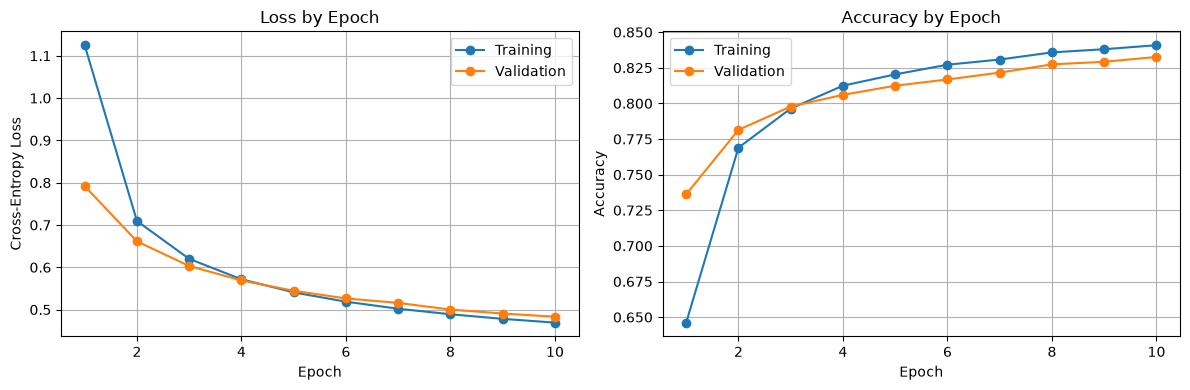

Best validation loss: 0.4832 at epoch 10


In [25]:
# Milestone 9: run a complete 10-epoch training experiment and save its history.

# Train long enough to see a trend, while keeping the first experiment small.
NUM_EPOCHS = 10

# Start this experiment from fresh weights, not from the earlier one-epoch example.
random_numbers = np.random.default_rng(SEED)
W1 = random_numbers.standard_normal((INPUT_SIZE, HIDDEN_SIZE)).astype(np.float32)
W1 *= np.sqrt(2.0 / INPUT_SIZE)
b1 = np.zeros((1, HIDDEN_SIZE), dtype=np.float32)
W2 = random_numbers.standard_normal((HIDDEN_SIZE, NUM_CLASSES)).astype(np.float32)
W2 *= np.sqrt(2.0 / HIDDEN_SIZE)
b2 = np.zeros((1, NUM_CLASSES), dtype=np.float32)

# Reset the batch shuffle order too, so this whole experiment is reproducible.
training_rng = np.random.default_rng(SEED + 1)

# Empty lists will store one metric value from each completed epoch.
training_loss_history = []
training_accuracy_history = []
validation_loss_history = []
validation_accuracy_history = []

# Start with infinity so the first validation loss is always considered the best.
best_validation_loss = np.inf
best_epoch = 0

# These copies will hold the parameters from the best validation epoch.
best_W1 = None
best_b1 = None
best_W2 = None
best_b2 = None

# Repeat training and validation 10 times.
for epoch_number in range(1, NUM_EPOCHS + 1):
    # Learn from all 55,000 training examples once.
    W1, b1, W2, b2, training_loss, training_accuracy = train_one_epoch(
        X_train,
        y_train,
        W1,
        b1,
        W2,
        b2,
        LEARNING_RATE,
        BATCH_SIZE,
    )

    # Measure the model on validation examples without changing any parameters.
    validation_loss, validation_accuracy = evaluate(
        X_validation,
        y_validation,
        W1,
        b1,
        W2,
        b2,
    )

    # Save this epoch's four metrics for plots and later comparison.
    training_loss_history.append(training_loss)
    training_accuracy_history.append(training_accuracy)
    validation_loss_history.append(validation_loss)
    validation_accuracy_history.append(validation_accuracy)

    # Keep copies of the parameters only when validation loss improves.
    if validation_loss < best_validation_loss:
        best_validation_loss = validation_loss
        best_epoch = epoch_number
        best_W1 = W1.copy()
        best_b1 = b1.copy()
        best_W2 = W2.copy()
        best_b2 = b2.copy()

    # Show the experiment's progress after every epoch.
    print(
        f"Epoch {epoch_number:2d}/{NUM_EPOCHS} | "
        f"train loss: {training_loss:.4f} | "
        f"train accuracy: {training_accuracy:.2%} | "
        f"validation loss: {validation_loss:.4f} | "
        f"validation accuracy: {validation_accuracy:.2%}"
    )

# Check that we saved exactly one result per epoch and one best parameter set.
assert len(training_loss_history) == NUM_EPOCHS
assert len(validation_loss_history) == NUM_EPOCHS
assert best_W1 is not None

# Make x-axis values 1 through 10 for the learning-curve plots.
epoch_numbers = np.arange(1, NUM_EPOCHS + 1)

# Create two side-by-side plots: loss on the left and accuracy on the right.
figure, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot training and validation loss. Lower is better.
axes[0].plot(epoch_numbers, training_loss_history, marker="o", label="Training")
axes[0].plot(epoch_numbers, validation_loss_history, marker="o", label="Validation")
axes[0].set_title("Loss by Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True)

# Plot training and validation accuracy. Higher is better.
axes[1].plot(epoch_numbers, training_accuracy_history, marker="o", label="Training")
axes[1].plot(epoch_numbers, validation_accuracy_history, marker="o", label="Validation")
axes[1].set_title("Accuracy by Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print(f"Best validation loss: {best_validation_loss:.4f} at epoch {best_epoch}")

## Milestone 3 checkpoint

The model can now turn normalized pixels into probabilities and measure its own error with cross-entropy loss. Its weights are still random, so it cannot learn yet. The next milestone is backpropagation: calculate how each weight and bias contributed to the loss, then use those gradients to improve them.